# Titanic EDA Lab

### Having insights into your data can be the difference between sinking or swimming on a project. Here we'll dive into some Exploratory Data Analysis techniques on the iconic Titanic data set.


## Step 1: Reading the data

1. Go to [https://www.kaggle.com/c/titanic/data](https://www.kaggle.com/c/titanic/data)
2. If you scroll down the page a bit, you'll see a data dictionary explaining each of the columns. Take a minute to familiarize yourself with how the csv is structured.
3. Download the `train.csv` file into this project
4. Load the csv into pandas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('./train.csv')

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 2: Cleaning the data
Note: `NaN`, empty, and missing are synonymous.

2a) Create a bar chart showing how many missing values are in each column

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


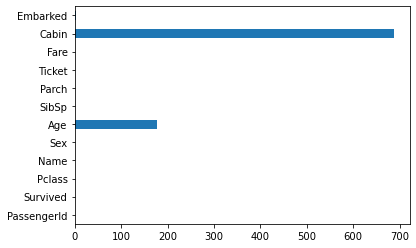

In [7]:
df.isnull().sum().plot(kind='barh');

2b) Which column has the most `NaN` values? How many cells in that column are empty?

2c) Delete all rows where `Embarked` is empty

In [10]:
df.dropna(subset=['Embarked'], inplace=True)

2d) Fill all empty cabins with **¯\\_(ツ)_/¯**

In [11]:
df['Cabin'].fillna('¯\\(ツ)/¯', inplace = True)

## Step 3: Feature extraction
3a)  There are two columns that pertain to how many family members are on the boat for a given person. Create a new column called `FamilyCount` which will be the sum of those two columns.

for idx, row in df.iterrows():

    for i in range(something else):
    
        ?

In [13]:
df['FamilyCount'] = df['Parch'] + df['SibSp']

3b) Reverends have a special title in their name. Create a column called `IsReverend`: 1 if they're a preacher, 0 if they're not.

3c) In order to feed our training data into a classification algorithm, we need to convert our categories into 1's and 0's using `pd.get_dummies`
  1. Create 3 columns: `Embarked_C`, `Embarked_Q` and `Embarked_S`. These columns will have 1's and 0's that correspond to the `C`, `Q` and `S` values in the `Embarked` column
  

In [16]:
dummies = pd.get_dummies(df, columns=['Embarked', 'Sex'], dtype='int')
dummies.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,FamilyCount,Embarked_C,Embarked_Q,Embarked_S,Sex_female,Sex_male
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,¯\(ツ)/¯,1,0,0,1,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,1,1,0,0,1,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,¯\(ツ)/¯,0,0,0,1,1,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,1,0,0,1,1,0
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,¯\(ツ)/¯,0,0,0,1,0,1


In [21]:
dummies['Sex']=df['Sex']

  2. Do the same thing for `Sex`
  

  3. BONUS: Extract the title from everyone's name and create dummy columns

In [39]:
df['Name'].sample(15)

784                                    Ali, Mr. William
234                   Leyson, Mr. Robert William Norman
689                   Madill, Miss. Georgette Alexandra
489               Coutts, Master. Eden Leslie "Neville"
525                                  Farrell, Mr. James
407                      Richards, Master. William Rowe
366    Warren, Mrs. Frank Manley (Anna Sophia Atkinson)
326                           Nysveen, Mr. Johan Hansen
16                                 Rice, Master. Eugene
870                                   Balkic, Mr. Cerin
568                                 Doharr, Mr. Tannous
324                            Sage, Mr. George John Jr
855                          Aks, Mrs. Sam (Leah Rosen)
637                                 Collyer, Mr. Harvey
695                          Chapman, Mr. Charles Henry
Name: Name, dtype: object

In [40]:
df['Title']= [name.split(',')[1].split('.')[0] for name in df['Name']]

In [41]:
df['Title']

0         Mr
1        Mrs
2       Miss
3        Mrs
4         Mr
       ...  
886      Rev
887     Miss
888     Miss
889       Mr
890       Mr
Name: Title, Length: 889, dtype: object

## Step 4: Exploratory analysis
4a) What was the survival rate overall?

In [18]:
dummies['Survived'].mean()

0.38245219347581555

In [19]:
len(dummies)

889

4b) Which gender fared the worst? What was their survival rate?

Not the survival rate!

out of all the female passengers -- how many survived?

females who survived / all the female passengers

In [25]:
dummies.groupby('Sex').mean(numeric_only=True)['Survived']

Sex
female    0.740385
male      0.188908
Name: Survived, dtype: float64

4c) What was the survival rate for each `Pclass`?

4d) Did any reverends survive? How many?

4e) What is the survival rate for cabins marked **¯\\_(ツ)_/¯**

4f) What is the survival rate for people whose `Age` is empty?

4g) What is the survival rate for each port of embarkation?

In [26]:
df['Embarked']

0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 889, dtype: object

In [28]:
df.groupby('Embarked').mean(numeric_only=True)['Survived']

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

In [30]:
for col in ['Embarked_C', 'Embarked_Q', 'Embarked_S']:
    print(col, ':')
    print(dummies[dummies[col] == 1][['Survived']].mean())
    print()

Embarked_C :
Survived    0.553571
dtype: float64

Embarked_Q :
Survived    0.38961
dtype: float64

Embarked_S :
Survived    0.336957
dtype: float64



4h) What is the survival rate for children (under 12) in each `Pclass`?

In [35]:
dummies[dummies['Age']<12].groupby('Pclass').mean(numeric_only=True)['Survived']

Pclass
1    0.750000
2    1.000000
3    0.404255
Name: Survived, dtype: float64

4i) Did the captain of the ship survive? Is he on the list?

4j) Of all the people that died, who had the most expensive ticket? How much did it cost?

4k) Does having family on the boat help or hurt your chances of survival?

## Step 5: Plotting
Using Matplotlib and Seaborn, create several charts showing the survival rates of different groups of people. It's fine if a handful of charts are basic (Gender, Age, etc), but what we're really looking for is something beneath the surface.

*Note: Answers may vary*
